In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (6,3)

In [57]:
def plot_data(df, x, y, title, x_label, y_label):
    fig, ax = plt.subplots()
    for key, grp in df.groupby(['optimizer']):
        ax = grp.plot(ax=ax, kind='line', x=x, y=y, label=key[0])
    ax.set_title(title, fontdict={'fontweight':'bold'})
    ax.set_xlabel(xlabel=x_label)
    ax.xaxis.get_label().set_fontstyle('italic')
    ax.yaxis.get_label().set_fontstyle('italic')
    ax.set_ylabel(ylabel=y_label)
    ax.grid(visible=True)
    plt.legend(loc='best')    
    plt.show()


In [58]:
df = pd.read_csv('results-final.csv')
df['training_time'] = df['training_time'].divide(3600)
df = df.round(4)

In [59]:
df.sort_values(['r2'], ascending=False)

,n_features,n_targets,n_samples,test_size,optimizer,iterations,training_time,prediction_time,r2,mae,mse,rmse
69,3,2,500,30,lbfgsb,500,3.0381,0.3317,0.9504,0.0377,0.0029,0.0539
62,3,2,500,30,lbfgsb,300,3.4232,0.3060,0.9501,0.0378,0.0029,0.0540
46,3,2,500,30,lbfgsb,100,2.4656,0.3058,0.9461,0.0398,0.0031,0.0561
76,3,2,500,30,slsqp,500,0.7934,0.3114,0.9415,0.0438,0.0034,0.0586
74,3,2,500,30,slsqp,300,0.8991,0.3037,0.9407,0.0418,0.0035,0.0588
70,3,2,500,30,slsqp,100,0.6677,0.3150,0.9381,0.0423,0.0036,0.0601
40,3,2,500,40,lbfgsb,100,2.0474,0.4342,0.9369,0.0496,0.0039,0.0624
75,3,2,500,40,lbfgsb,500,3.7445,0.3938,0.9368,0.0497,0.0039,0.0625
64,3,2,500,40,lbfgsb,300,4.7603,0.4112,0.9368,0.0497,0.0039,0.0625
77,3,2,500,40,slsqp,100,0.8704,0.3931,0.9337,0.0496,0.0041,0.0641


In [62]:
"""
sample_sizes = [100, 500, 1000]
test_sizes = [20, 30, 40]
"""
pd.set_option('display.max_rows', None)
df[(df['n_samples']==100)].to_html('100_samples.html', index=False)
df[(df['n_samples']==500)].to_html('500_samples.html', index=False)
df[(df['n_samples']==1000)].to_html('1000_samples.html', index=False)

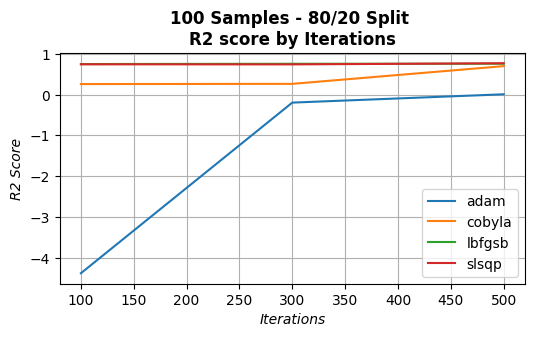

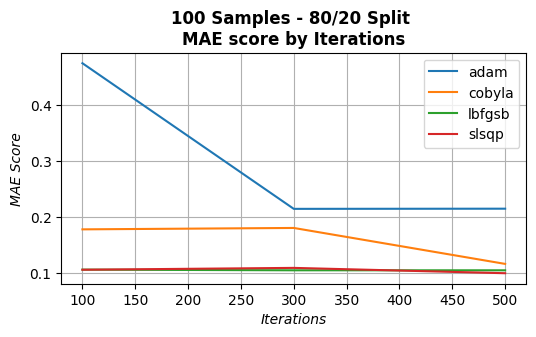

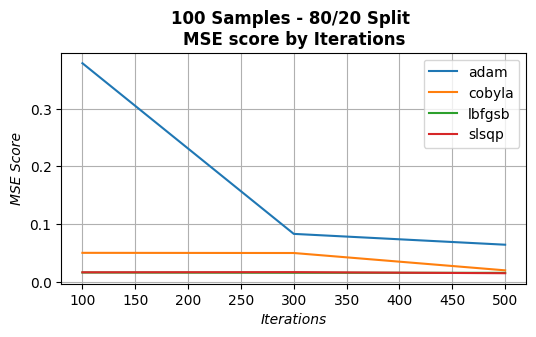

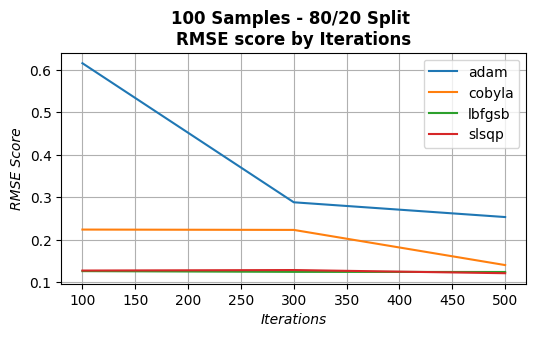

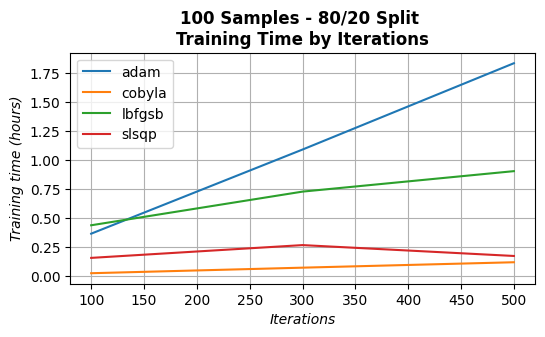

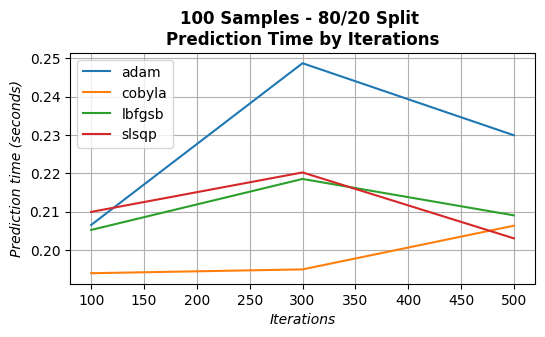

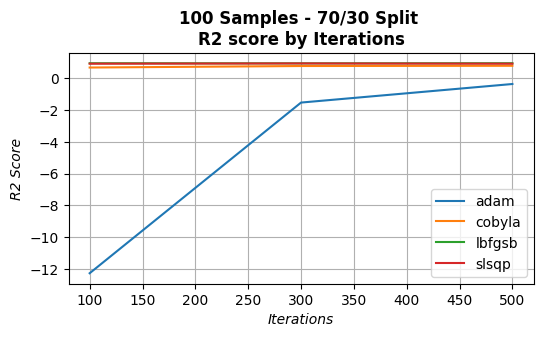

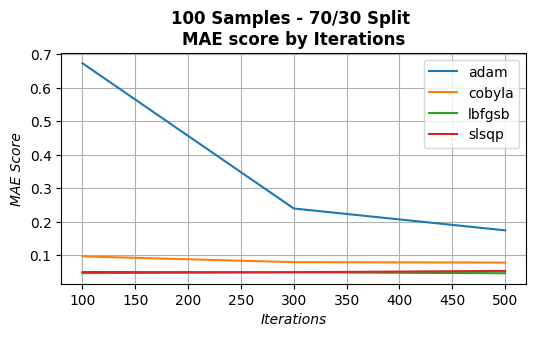

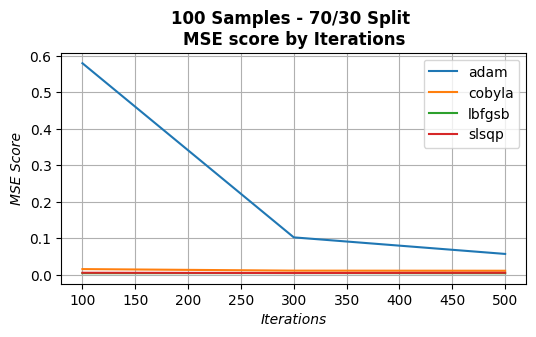

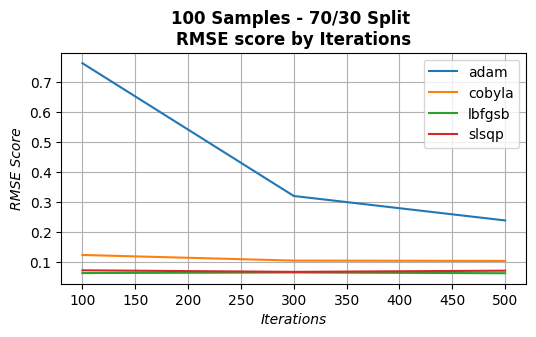

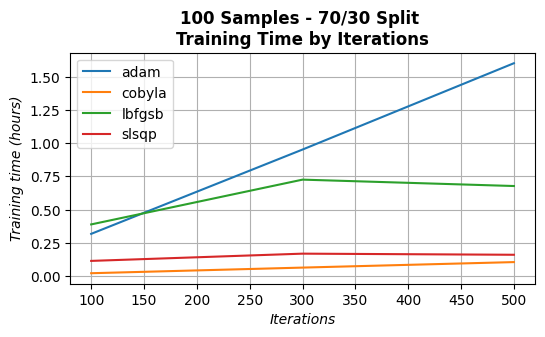

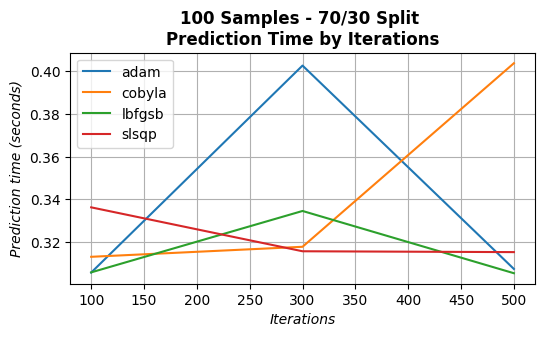

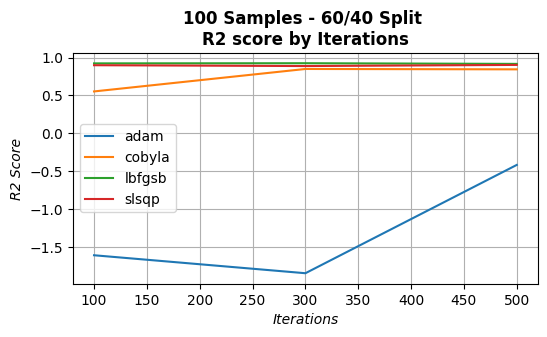

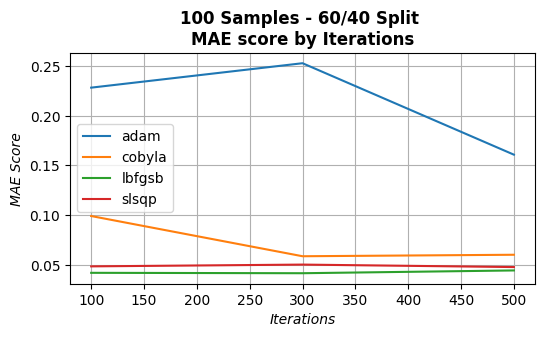

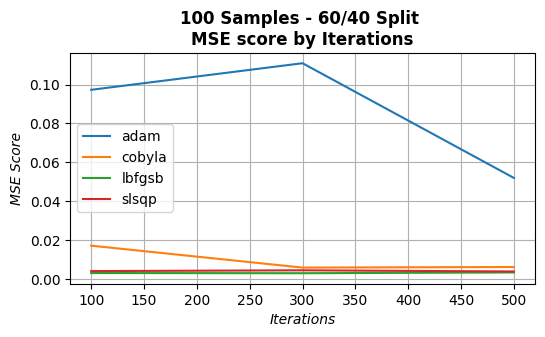

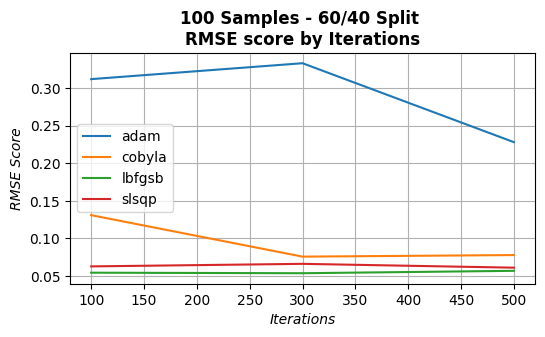

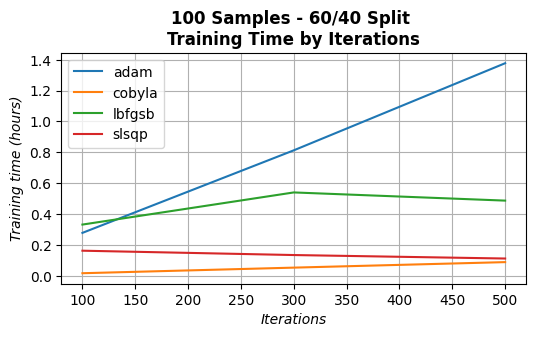

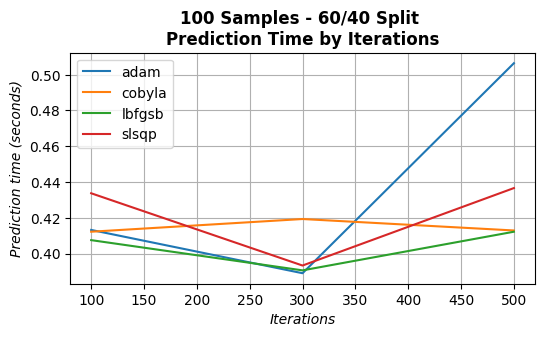

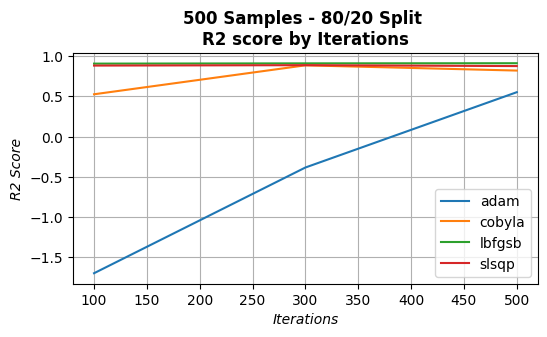

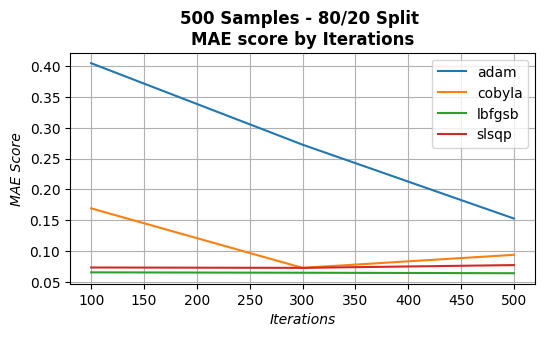

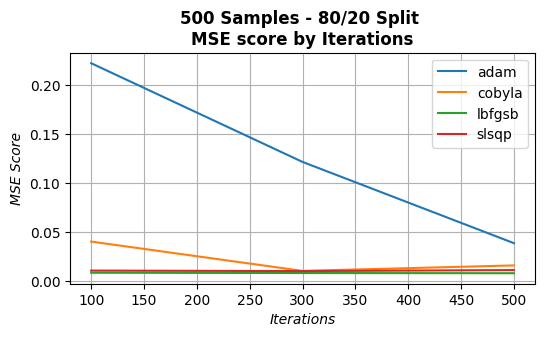

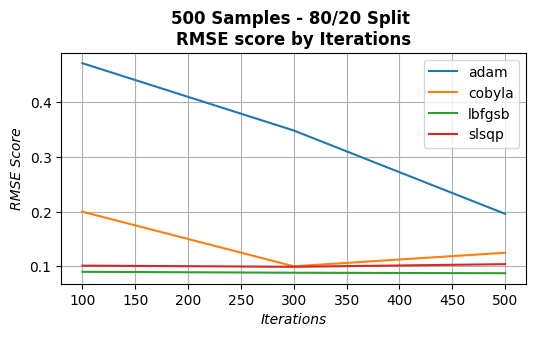

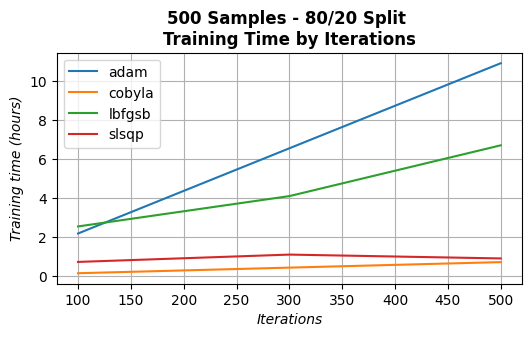

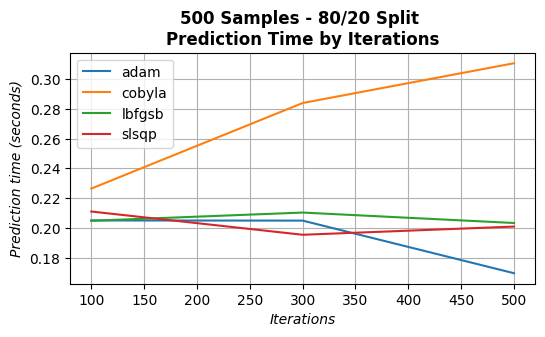

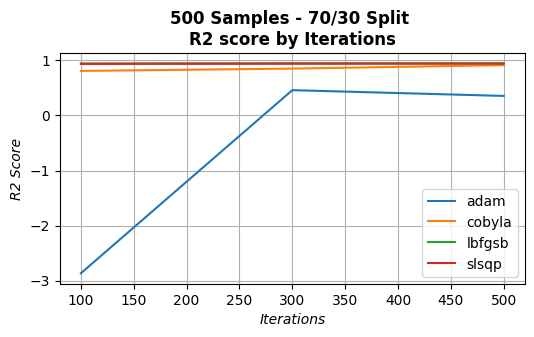

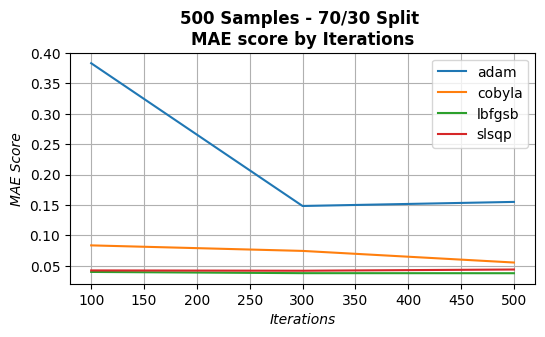

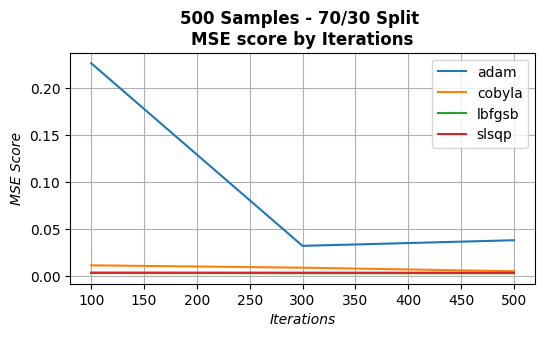

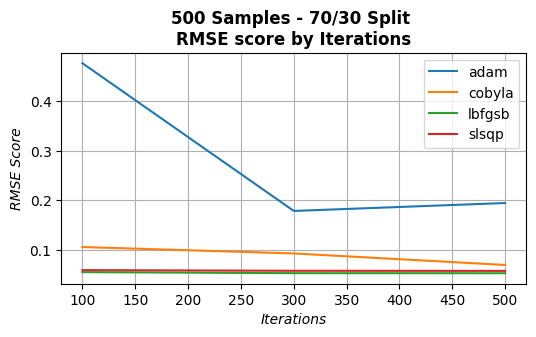

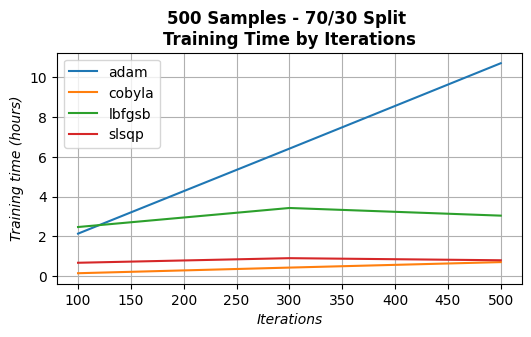

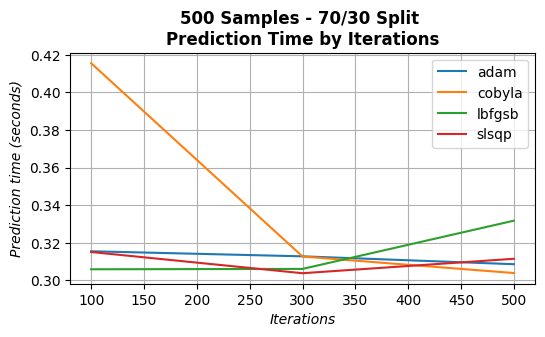

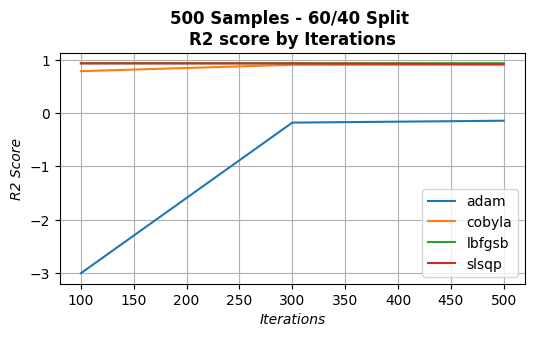

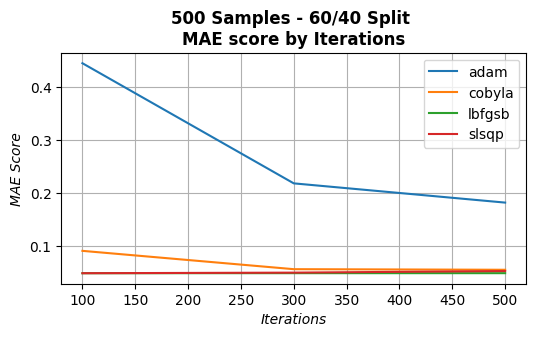

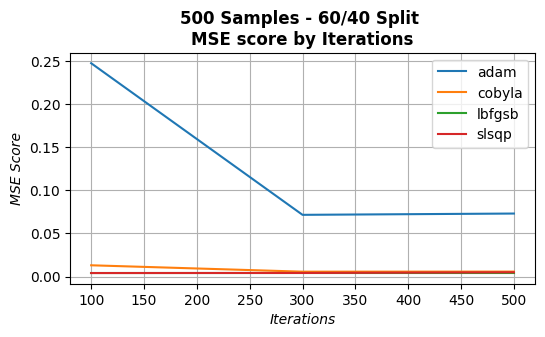

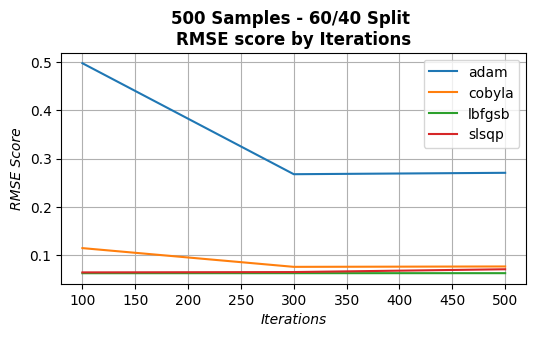

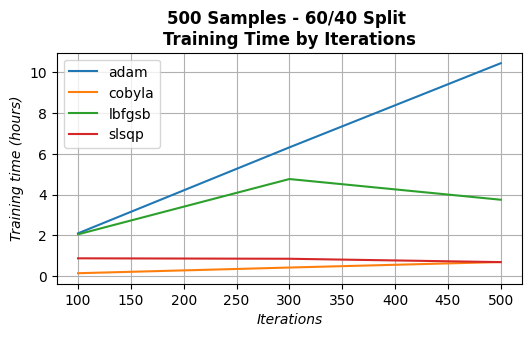

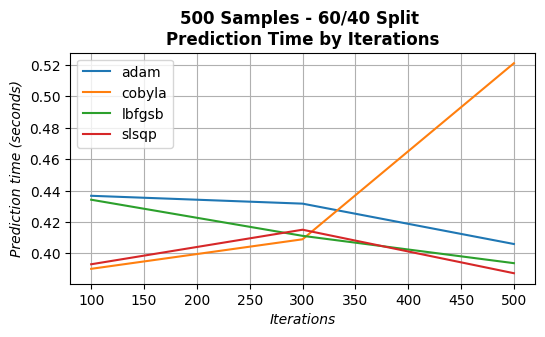

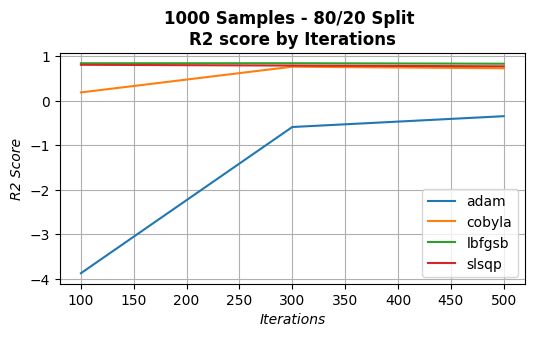

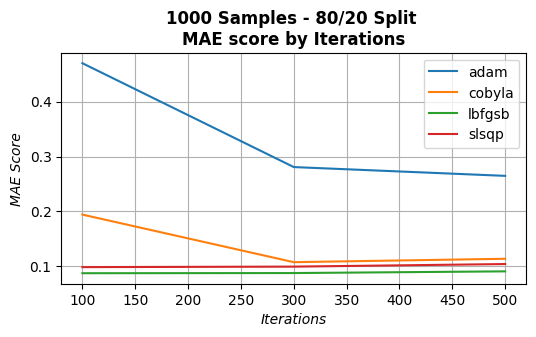

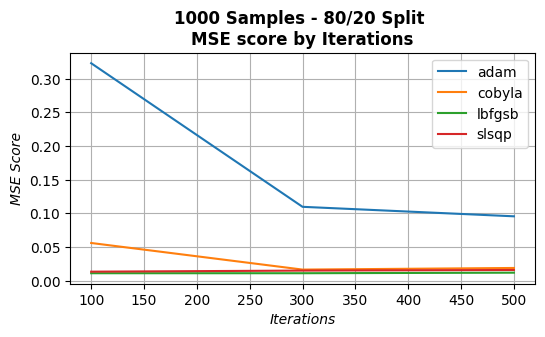

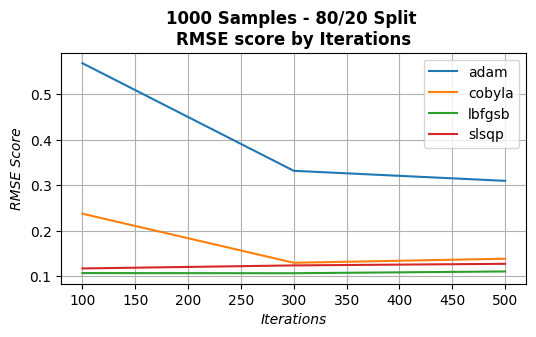

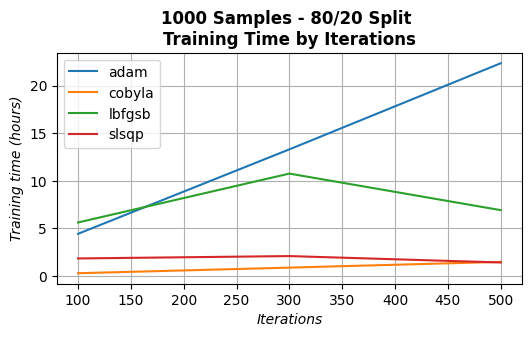

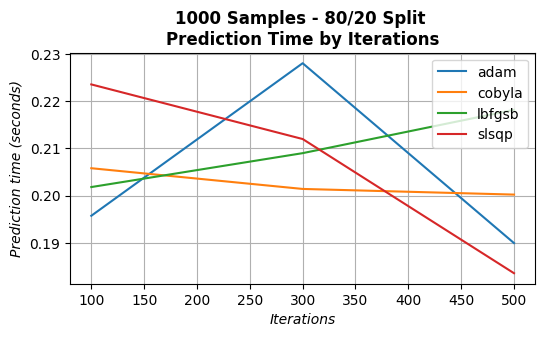

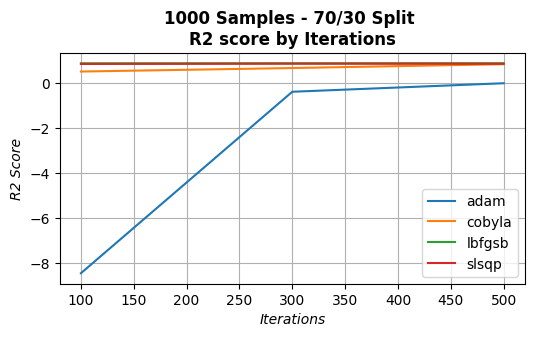

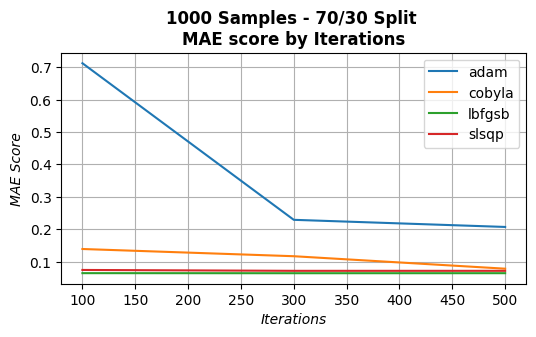

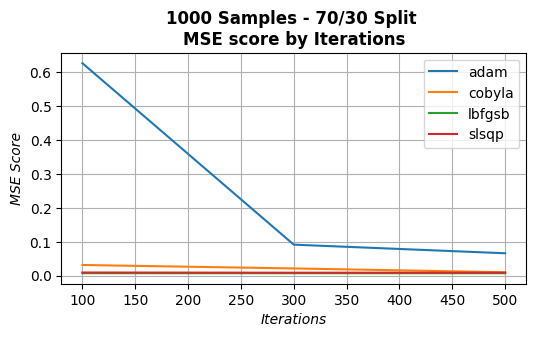

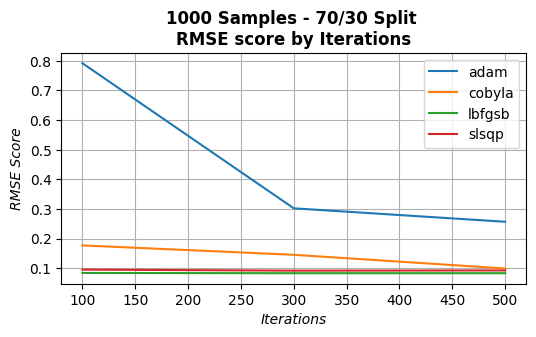

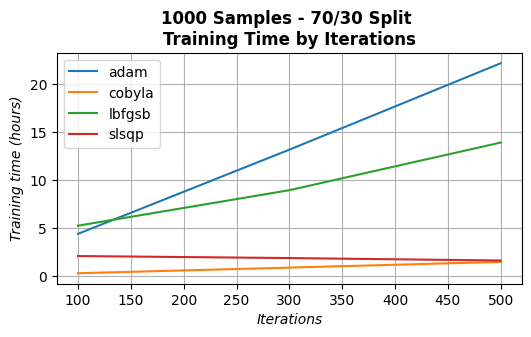

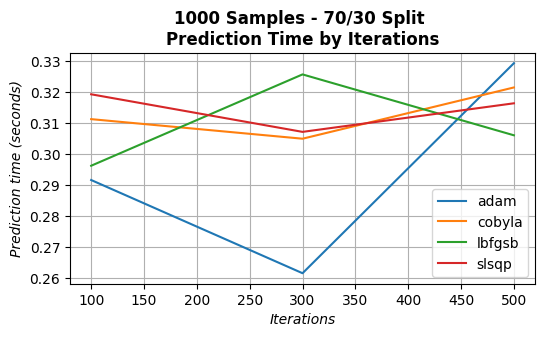

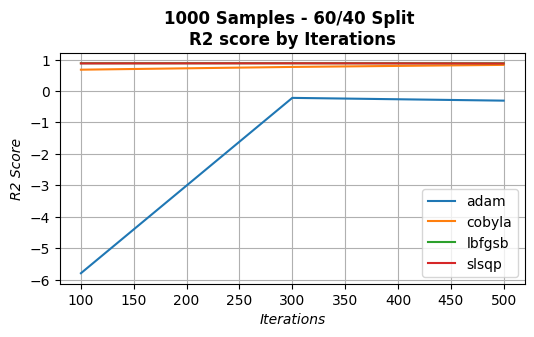

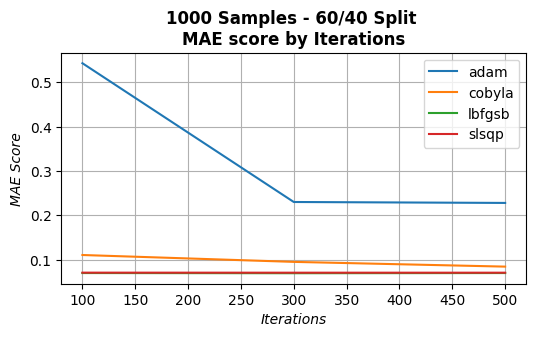

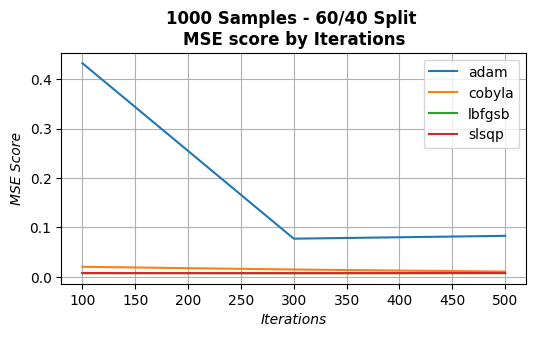

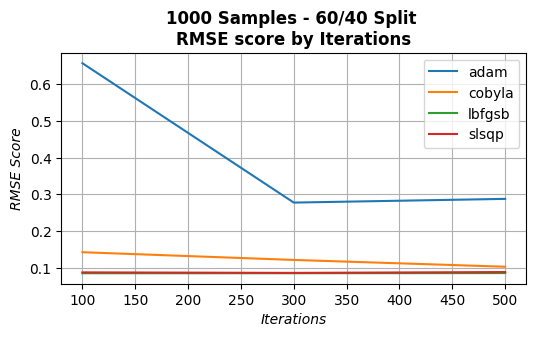

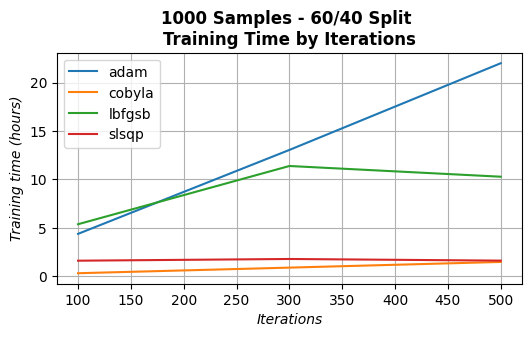

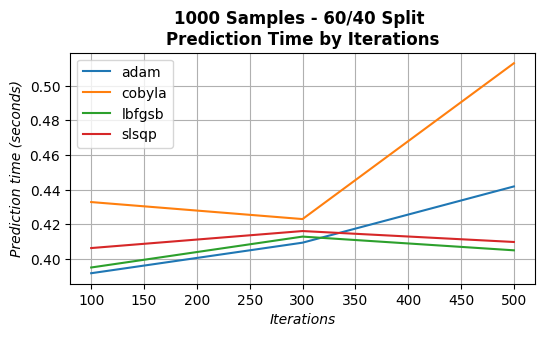

In [61]:
sample_sizes = [100, 500, 1000]
test_sizes = [20, 30, 40]
performance_metrics = ['r2', 'mae', 'mse', 'rmse']
for sample_size in sample_sizes:
    for test_size in test_sizes:
        df_nsamples_by_split = df[(df['n_samples']==sample_size) & (df['test_size'] == test_size)]
        for performance_metric in performance_metrics:
            plot_data(df_nsamples_by_split, 'iterations', performance_metric, f'{sample_size} Samples - {100-test_size}/{test_size} Split \n{performance_metric.upper()} score by Iterations', 'Iterations', f'{performance_metric.upper()} Score')
        plot_data(df_nsamples_by_split, 'iterations', 'training_time', f"{sample_size} Samples - {100-test_size}/{test_size} Split \nTraining Time by Iterations", "Iterations", "Training time (hours)")
        plot_data(df_nsamples_by_split, 'iterations', 'prediction_time', f"{sample_size} Samples - {100-test_size}/{test_size} Split \nPrediction Time by Iterations", "Iterations", "Prediction time (seconds)")